# Clustering, cliques, k-core y comunidades en la red de dinastías

**CD.30 Redes Complejas · Maestría en Ciencia de Datos · ITBA**

Segunda parte del análisis de la red genealógica de nobles y gobernantes (siglos VI a XV) construida a partir de Wikidata. En la primera (`01 - Metricas`) calculamos grado, caminos, conectividad, clustering y centralidad. Acá pasamos de los nodos a los grupos: buscamos conjuntos de personas cohesivos y algoritmos que los encuentren sin mirar el dibujo.

Como en la primera parte, todo se calcula para **tres redes**: el **Mundo** (la red completa) y los subgrafos de **Asia** y **Europa** según la columna `continente`. Usamos siempre las funciones de `networkx` (y `scipy` donde networkx sería demasiado lento para 18.000 nodos).

**Plan**

0. Leer las redes.
1. Coeficiente de clustering y comparación con redes al azar (#3A).
2. Cliques (#3B).
3. k-core (#3B).
4. Comunidades: cortar los puentes con Girvan–Newman (#3C).
5. Modularidad (#3C).
6. Algoritmo de Louvain (#3C).
7. Mundo, Asia y Europa.

## 0. Leer las redes

Usamos los archivos de `csv-finales/`. Cada nodo es una persona y cada enlace un vínculo familiar: hermano (peso 1), cónyuge (peso 2) o padre/madre (peso 3). Como en la primera parte, trabajamos con la red **no dirigida** y, cuando un par tiene dos vínculos, nos quedamos con el de mayor peso.

In [ ]:
%pip install -q networkx pandas numpy matplotlib scipy

In [2]:
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.sparse.csgraph import shortest_path

SEMILLA = 42
REGIONES = ["Mundo", "Asia", "Europa"]
COLORES = {"Mundo": "tab:gray", "Asia": "tab:red", "Europa": "tab:blue"}
plt.rcParams["figure.dpi"] = 90

CANDIDATAS = [Path("../csv-finales"), Path("csv-finales"), Path(".")]
CARPETA_DATOS = next(p for p in CANDIDATAS if (p / "nodos_finales_completos.csv").exists())
nodos = pd.read_csv(CARPETA_DATOS / "nodos_finales_completos.csv")
relaciones = pd.read_csv(CARPETA_DATOS / "relaciones_limpias.csv")

def construir_grafo(nodos, relaciones):
    pares = np.sort(relaciones[["Source", "Target"]].values, axis=1)
    aristas = (relaciones.assign(u=pares[:, 0], v=pares[:, 1])
                         .groupby(["u", "v"])
                         .agg(weight=("Weight", "max"), tipo=("Label", lambda s: "+".join(sorted(set(s)))))
                         .reset_index())
    G = nx.from_pandas_edgelist(aristas, "u", "v", edge_attr=["weight", "tipo"])
    G.add_nodes_from(nodos["Id"])
    for attr, col in {"label": nodos["Label"], "casa": nodos["casa"].fillna(""),
                      "continente": nodos["continente"], "anio": nodos["anio"]}.items():
        nx.set_node_attributes(G, dict(zip(nodos["Id"], col)), attr)
    return G

def inducido(G, seleccion):
    # Subgrafo inducido que conserva el orden de los nodos de G. G.subgraph() recorre los nodos en el
    # orden de un set, que cambia en cada ejecución, y eso vuelve no reproducibles los resultados con semilla.
    seleccion = set(seleccion)
    H = G.__class__()
    H.add_nodes_from((v, d) for v, d in G.nodes(data=True) if v in seleccion)
    H.add_edges_from((u, v, d) for u, v, d in G.edges(data=True) if u in seleccion and v in seleccion)
    return H

def subred(G, continente):
    return inducido(G, [v for v, c in G.nodes(data="continente") if c == continente])

def gigante(G):
    return inducido(G, max(nx.connected_components(G), key=len))

def nombre(G, v):
    return G.nodes[v]["label"]

def resolver(G, nombre_o_id):
    # Id de una persona a partir de su Id o de su nombre exacto (hay nombres repetidos: en ese caso, usar el Id)
    if nombre_o_id in G:
        return nombre_o_id
    ids = [v for v in G if G.nodes[v]["label"] == nombre_o_id]
    if len(ids) != 1:
        raise ValueError(f"'{nombre_o_id}': {len(ids)} coincidencias {ids[:10]}")
    return ids[0]

mundo = construir_grafo(nodos, relaciones)
redes = {"Mundo": mundo, "Asia": subred(mundo, "Asia"), "Europa": subred(mundo, "Europa")}

for region, G in redes.items():
    N, L = G.number_of_nodes(), G.number_of_edges()
    print(f"{region:7s}: N = {N:5d}, L = {L:5d}, <k> = {2 * L / N:.2f}, "
          f"componentes = {nx.number_connected_components(G)}, gigante = {len(gigante(G))}")

Mundo  : N = 18060, L = 46760, <k> = 5.18, componentes = 74, gigante = 15242
Asia   : N =  4275, L = 14728, <k> = 6.89, componentes = 110, gigante = 1362
Europa : N = 13785, L = 31197, <k> = 4.53, componentes = 80, gigante = 13578


Con más de 15.000 nodos no se puede dibujar la red entera de forma legible (y el layout tardaría muchísimo). Como en la primera parte, dibujamos un **núcleo** de cada red: las 600 personas más cercanas a la de mayor betweenness (aproximada) de la componente gigante. Fijamos su posición (layout spring con semilla fija) y la usamos en todos los dibujos, así los colores de distintas secciones se pueden comparar. El tamaño de cada nodo es proporcional a su grado en la red completa.

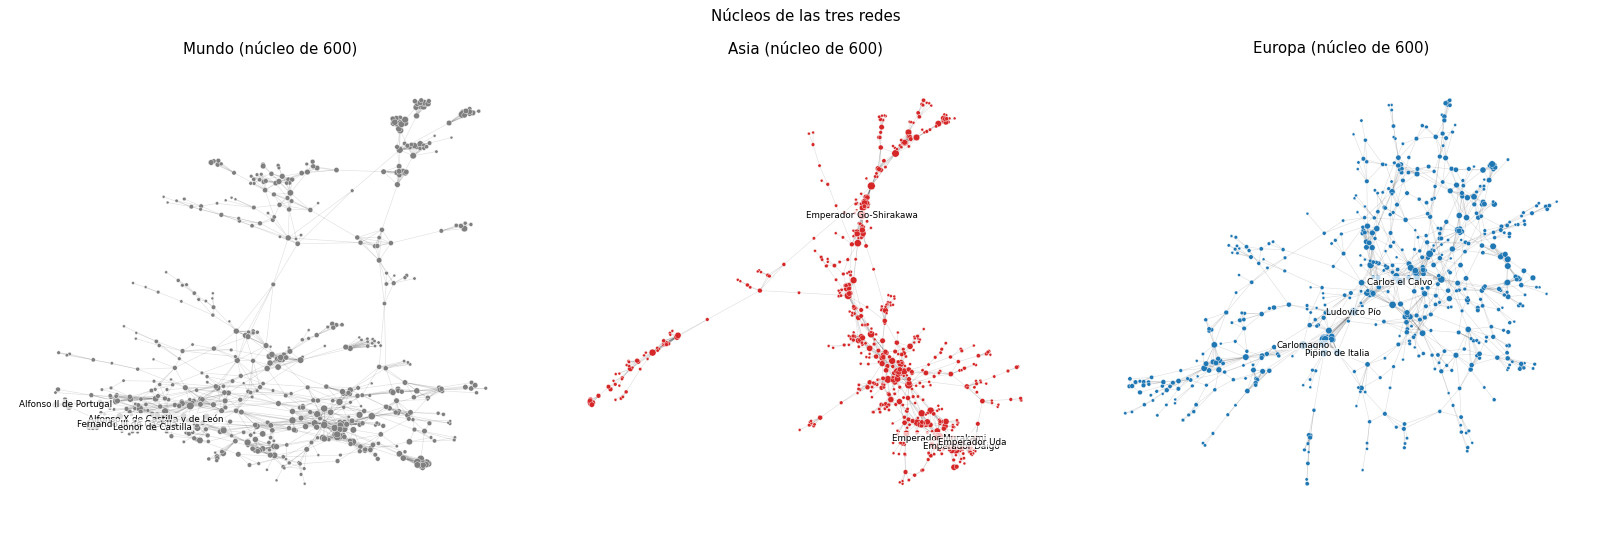

In [3]:
TAMANO_NUCLEO = 600

def nucleo(G, n=TAMANO_NUCLEO):
    Gg = gigante(G)
    bet = nx.betweenness_centrality(Gg, k=min(100, len(Gg)), seed=SEMILLA)
    centro = max(bet, key=bet.get)
    cercanos = list(nx.single_source_shortest_path_length(Gg, centro))[:n]   # orden BFS = por distancia
    return inducido(Gg, cercanos)

nucleos = {region: nucleo(G) for region, G in redes.items()}
posiciones = {region: nx.spring_layout(H, seed=SEMILLA, k=0.15, iterations=100) for region, H in nucleos.items()}

def dibujar(color=None, titulo="", cmap="tab20", vmin=None, vmax=None, barra=False, n_etiquetas=4):
    # Dibuja los tres núcleos. color: diccionario region -> (diccionario nodo -> número), o None
    fig, axs = plt.subplots(1, 3, figsize=(18, 6))
    for ax, region in zip(axs, REGIONES):
        H, pos, G = nucleos[region], posiciones[region], redes[region]
        c = None if color is None else color[region]
        orden = list(H) if c is None else sorted(H, key=lambda v: c[v])        # los valores altos arriba
        nx.draw_networkx_edges(H, pos, ax=ax, alpha=0.12, width=0.5)
        dibujo = nx.draw_networkx_nodes(
            H, pos, nodelist=orden, ax=ax, node_size=[4 + 1.5 * G.degree(v) for v in orden],
            node_color=COLORES[region] if c is None else [c[v] for v in orden],
            cmap=None if c is None else cmap, vmin=vmin, vmax=vmax, edgecolors="white", linewidths=0.3)
        top = sorted(H, key=G.degree, reverse=True)[:n_etiquetas]
        nx.draw_networkx_labels(H, pos, labels={v: nombre(H, v) for v in top}, font_size=7, ax=ax,
                                bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=0.4))
        if barra and c is not None:
            fig.colorbar(dibujo, ax=ax, shrink=0.6)
        ax.set_title(f"{region} (núcleo de {H.number_of_nodes()})")
        ax.axis("off")
    fig.suptitle(titulo)
    plt.tight_layout(); plt.show()

dibujar(titulo="Núcleos de las tres redes")

## 1. Coeficiente de clustering (#3A)

El clustering local mide qué fracción de los pares de vecinos de un nodo están conectados entre sí (Watts y Strogatz, 1998):

$$C_i = \frac{2\,T_i}{k_i\,(k_i-1)},$$

donde $k_i$ es el grado del nodo $i$ y $T_i$ es la cantidad de enlaces entre sus vecinos, es decir, la cantidad de triángulos que pasan por $i$. $C_i = 1$ si todos sus vecinos se conocen y $C_i = 0$ si ninguno se conoce. Si $k_i < 2$ no hay pares, y `networkx` define $C_i = 0$.

Lo miramos para algunas personas con `nx.clustering` y `nx.triangles`.

In [4]:
def mostrar_clustering(G, v):
    k = G.degree(v)
    print(f"{nombre(G, v):30s} k = {k:3d}, pares de vecinos = {k * (k - 1) // 2:5d}, "
          f"triángulos T = {nx.triangles(G, v):5d}, C = {nx.clustering(G, v):.3f}")

for persona in ["Carlomagno", "Song Huizong", "Gengis Kan", "Hugo Capeto"]:
    mostrar_clustering(mundo, resolver(mundo, persona))

# Alguien con muchos vínculos y C = 1
C_mundo = nx.clustering(mundo)
ejemplo = max((v for v in mundo if C_mundo[v] == 1), key=mundo.degree)
mostrar_clustering(mundo, ejemplo)
print("   sus vínculos:", Counter(mundo[ejemplo][w]["tipo"] for w in mundo[ejemplo]))

Carlomagno                     k =  27, pares de vecinos =   351, triángulos T =   105, C = 0.299
Song Huizong                   k = 100, pares de vecinos =  4950, triángulos T =  2576, C = 0.520
Gengis Kan                     k =  29, pares de vecinos =   406, triángulos T =    88, C = 0.217
Hugo Capeto                    k =   9, pares de vecinos =    36, triángulos T =    20, C = 0.556


Xishu Diji                     k =  68, pares de vecinos =  2278, triángulos T =  2278, C = 1.000
   sus vínculos: Counter({'hermano': 68})


En una genealogía los triángulos tienen un origen muy concreto:

- **Los hermanos forman cliques**: en los datos, cada hermano está unido con todos los demás. Alguien que sólo tiene registrados a sus hermanos tiene $C = 1$.
- **Padre, madre e hijo** forman un triángulo cuando también está registrado el matrimonio.
- Una persona con hijos de **varios cónyuges** tiene $C$ más bajo: los hijos de distintos matrimonios no siempre están unidos entre sí.

### Dos promedios para toda la red

El clustering medio $\langle C\rangle$ es el promedio de los $C_i$. La transitividad es $3\times$(triángulos)/(tripletes conectados): junta los pares de vecinos de toda la red antes de dividir, y por eso pesan más los nodos de grado alto. El gráfico de $C_i$ contra $k_i$ muestra por qué los dos números son distintos.

,<C>,transitividad
Mundo,0.436,0.692
Asia,0.441,0.804
Europa,0.431,0.492


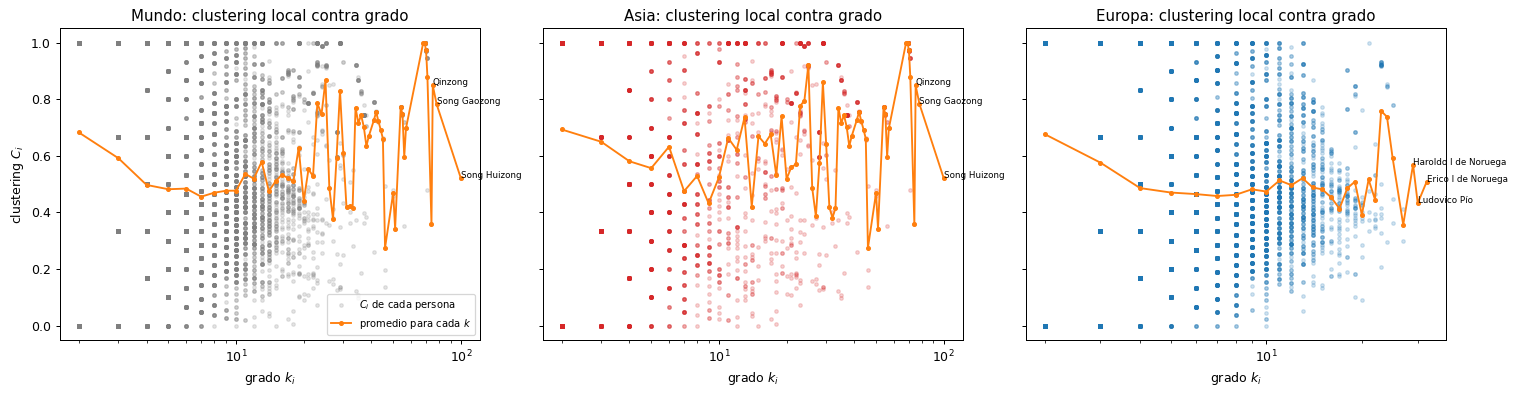

In [5]:
clustering = {region: nx.clustering(G) for region, G in redes.items()}
display(pd.DataFrame({region: {"<C>": nx.average_clustering(G), "transitividad": nx.transitivity(G)}
                      for region, G in redes.items()}).T.round(3))

fig, axs = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, (region, G) in zip(axs, redes.items()):
    k, C = dict(G.degree()), clustering[region]
    # Promedio de C_i para cada valor de k: la curva C(k). Para k < 2 el clustering no está definido.
    Ck = pd.DataFrame({"k": k, "C": C}).query("k >= 2").groupby("k")["C"].mean()
    ax.scatter([k[v] for v in G if k[v] >= 2], [C[v] for v in G if k[v] >= 2], s=8, alpha=0.2,
               color=COLORES[region], label="$C_i$ de cada persona")
    ax.plot(Ck.index, Ck.values, "o-", ms=3, color="tab:orange", label="promedio para cada $k$")
    for v in sorted(G, key=G.degree, reverse=True)[:3]:
        ax.annotate(nombre(G, v), (k[v], C[v]), fontsize=7)
    ax.set_xscale("log")
    ax.set(xlabel="grado $k_i$", title=f"{region}: clustering local contra grado")
axs[0].set_ylabel("clustering $C_i$")
axs[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

Para grados chicos e intermedios el clustering baja con el grado, como en casi todas las redes reales: quien tiene pocos vínculos suele tener sólo a su familia nuclear, que está toda conectada, y quien tiene más vínculos suele unir varias familias (sus padres y hermanos por un lado, sus cónyuges e hijos por otro). Pero en los grados más altos del Mundo y de Asia el clustering vuelve a subir: esos nodos son miembros de grupos enormes de hermanos (los hijos de los emperadores Song y Tang), que forman cliques. Por ejemplo, Xishu Diji tiene 68 vecinos y $C = 1$: todos son sus hermanos. En Europa, donde los grupos de hermanos registrados son más chicos, la curva es casi plana. Por eso, a diferencia de lo habitual, acá la **transitividad es mayor que $\langle C\rangle$**, sobre todo en Asia (0,80 contra 0,44).

### Para qué sirve: comparar con redes al azar

Un valor de $\langle C\rangle$ solo no dice si es alto o bajo. Lo comparamos con dos redes al azar:

- **Erdős–Rényi** con los mismos $N$ y $L$ (`nx.gnm_random_graph`). Cada par de nodos está conectado con la misma probabilidad $p = 2L/[N(N-1)]$, y entonces $\langle C\rangle \approx p$.
- Una red con **los mismos grados** $k_i$, recableada al azar con `nx.double_edge_swap`. Es la idea del modelo de configuración de la teórica #3C.

También medimos la distancia media $\langle d\rangle$ en la componente gigante. Con 15.000 nodos la calculamos con `scipy.sparse.csgraph.shortest_path` desde una muestra de 200 nodos de origen (el error es menor a una décima).

In [6]:
def distancia_media(G, fuentes=200):
    Gg = gigante(G)
    A = nx.to_scipy_sparse_array(Gg, weight=None, format="csr")
    rng = np.random.default_rng(SEMILLA)
    origenes = rng.choice(A.shape[0], size=min(fuentes, A.shape[0]), replace=False)
    D = shortest_path(A, directed=False, unweighted=True, indices=origenes)
    return D[D > 0].mean()

def comparar_con_azar(G, muestras=3):
    N, L = G.number_of_nodes(), G.number_of_edges()
    res = {"Erdős–Rényi (mismos N y L)": [], "mismos grados": []}
    for s in range(muestras):
        R = nx.gnm_random_graph(N, L, seed=s)
        H = G.copy()
        nx.double_edge_swap(H, nswap=5 * L, max_tries=100 * L, seed=s)   # recablea sin cambiar ningún k_i
        for modelo, red in [("Erdős–Rényi (mismos N y L)", R), ("mismos grados", H)]:
            res[modelo].append((nx.average_clustering(red), nx.transitivity(red), distancia_media(red)))
    tabla = {"red real": (nx.average_clustering(G), nx.transitivity(G), distancia_media(G))}
    tabla.update({modelo: np.mean(v, axis=0) for modelo, v in res.items()})
    return pd.DataFrame(tabla, index=["<C>", "transitividad", "<d>"]).T

pd.concat({region: comparar_con_azar(G) for region, G in redes.items()}).round(4)

<C>  transitividad      <d>
Mundo  red real                    0.4358         0.6918  14.6006
       Erdős–Rényi (mismos N y L)  0.0002         0.0003   6.1368
       mismos grados               0.0015         0.0018   4.9868
Asia   red real                    0.4414         0.8038  13.0047
       Erdős–Rényi (mismos N y L)  0.0019         0.0019   4.5523
       mismos grados               0.0175         0.0224   3.8928
Europa red real                    0.4309         0.4923  13.3283
       Erdős–Rényi (mismos N y L)  0.0002         0.0003   6.4870
       mismos grados               0.0005         0.0007   5.8746

El clustering de las redes reales es **entre cientos y miles de veces mayor** que el de Erdős–Rényi (0,44 contra 0,0002 en el Mundo) y también muy superior al de la red con los mismos grados: las redes al azar casi no tienen triángulos. Pero, a diferencia de una red social, las distancias reales son **más del doble** que en las redes al azar (unos 14 pasos contra 5 o 6 en el Mundo). Una genealogía no es un "mundo pequeño": los vínculos sólo unen generaciones vecinas, así que para ir de un extremo al otro hay que recorrer los siglos de a una generación. En la red recableada, cualquier persona puede quedar unida con alguien de otro siglo y otro continente, y los caminos se acortan.

Los triángulos son la primera señal de que la red tiene grupos cohesivos (hipótesis H3 de #3C), y es lo que buscamos en el resto del notebook.

## 2. Cliques (#3B)

Una clique es un conjunto de nodos donde todos están conectados con todos. Es maximal si no se le puede agregar ningún nodo sin romper esa propiedad. `nx.find_cliques` lista todas las cliques maximales (algoritmo de Bron–Kerbosch). Las cliques se pueden superponer: un nodo puede estar en muchas.

Mundo  : 13977 cliques maximales; la más grande tiene 69 personas
Asia   :  3306 cliques maximales; la más grande tiene 69 personas
Europa : 10577 cliques maximales; la más grande tiene 22 personas


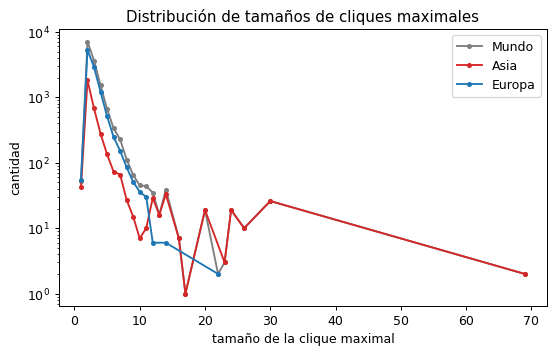

In [7]:
cliques = {region: list(nx.find_cliques(G)) for region, G in redes.items()}

fig, ax = plt.subplots(figsize=(7, 4))
for region in REGIONES:
    tamanos = Counter(len(q) for q in cliques[region])
    x = sorted(tamanos)
    ax.semilogy(x, [tamanos[t] for t in x], "o-", ms=3, label=region, color=COLORES[region])
    print(f"{region:7s}: {len(cliques[region]):5d} cliques maximales; la más grande tiene "
          f"{max(tamanos)} personas")
ax.set(xlabel="tamaño de la clique maximal", ylabel="cantidad", title="Distribución de tamaños de cliques maximales")
ax.legend(); plt.show()

In [8]:
def describir_clique(G, q):
    tipos = Counter(G[u][v]["tipo"] for u, v in G.subgraph(q).edges())
    casas = Counter(G.nodes[v]["casa"] for v in q if G.nodes[v]["casa"])
    anios = [G.nodes[v]["anio"] for v in q]
    print(f"   {len(q)} personas, años {min(anios)}–{max(anios)}, casas: {dict(casas.most_common(3))}")
    print(f"   enlaces internos por tipo: {dict(tipos)}")
    print(f"   con más vínculos: {', '.join(nombre(G, v) for v in sorted(q, key=G.degree, reverse=True)[:6])}")

for region in REGIONES:
    mayor = max(cliques[region], key=len)
    print(f"La clique más grande de {region}:")
    describir_clique(redes[region], mayor)

La clique más grande de Mundo:
   69 personas, años 1099–1131, casas: {'House of Zhao': 68}
   enlaces internos por tipo: {'hermano': 2346}
   con más vínculos: Song Gaozong, Qinzong, Princess Yanguo, Ande Diji, Rongde Diji, Maode Diji
La clique más grande de Asia:
   69 personas, años 1082–1131, casas: {'House of Zhao': 69}
   enlaces internos por tipo: {'hermano': 2278, 'padre': 68}
   con más vínculos: Song Huizong, Song Gaozong, Qinzong, Princess Yanguo, Maode Diji, Ande Diji
La clique más grande de Europa:
   22 personas, años 801–920, casas: {'Hårfagreætta': 21}
   enlaces internos por tipo: {'hermano': 231}
   con más vínculos: Erico I de Noruega, Bjørn Farmann, Ring Haraldsson, Ålov Haraldsdotter, Olaf Haraldsson Geirstadalf, Sigurd Rise


La clique más grande no es un grupo de gente que "se trata", sino **un grupo de hermanos, a veces con su padre**: los datos registran un enlace entre cada par de hermanos y uno de cada hijo con cada progenitor, así que una familia con $n$ hijos registrados es automáticamente una clique de $n$ personas, o de $n + 1$ y $n + 2$ si se suman el padre y la madre. En el Mundo y en Asia es la familia del emperador Song Huizong: hay dos cliques de 69 personas, una con 69 de sus hijos (todos hermanos entre sí) y otra con el emperador y 68 de sus hijos. En Europa es la de Haroldo I de Noruega. Es un efecto de cómo se construyó la red: antes de interpretar una estructura conviene mirar qué hay detrás.

Las cliques se superponen: una persona puede estar en muchas.

In [9]:
# En cuántas cliques maximales está cada persona
for region in REGIONES:
    pertenencia = Counter(v for q in cliques[region] for v in q)
    print(f"{region}: personas en más cliques maximales")
    for v, n in pertenencia.most_common(4):
        print(f"   {nombre(redes[region], v):35s} {n:3d} cliques   (k = {redes[region].degree(v)})")

Mundo: personas en más cliques maximales
   Su Zong                              31 cliques   (k = 71)
   Ninmyō                               30 cliques   (k = 35)
   Li Shimin                            29 cliques   (k = 74)
   Emperador Saga                       29 cliques   (k = 46)
Asia: personas en más cliques maximales
   Su Zong                              31 cliques   (k = 71)
   Ninmyō                               30 cliques   (k = 35)
   Princess Xianyi                      29 cliques   (k = 57)
   Li Mao                               29 cliques   (k = 57)
Europa: personas en más cliques maximales
   Estorre Visconti                     19 cliques   (k = 20)
   Ambrogio Visconti                    18 cliques   (k = 19)
   Boleslao I de Polonia                13 cliques   (k = 19)
   Rogelio II de Sicilia                13 cliques   (k = 24)


Quien está en muchas cliques maximales tiene hijos con varios cónyuges, o hermanos de varios matrimonios de sus padres: cada familia nuclear es una clique distinta y esa persona es la bisagra entre ellas.

### La clique es frágil

Para ser una clique tienen que estar todos los enlaces. Lo probamos con la clique más grande del Mundo: sacamos un solo enlace y buscamos de nuevo las cliques entre esas personas.

In [10]:
mayor = max(cliques["Mundo"], key=len)
H = inducido(mundo, mayor)
n = len(mayor)
u, v = sorted(mayor)[:2]
H.remove_edge(u, v)
print(f"Sacamos el enlace {nombre(H, u)} – {nombre(H, v)}")
print(f"Enlaces entre los {n}: {H.number_of_edges()} de {n * (n - 1) // 2} posibles")
print("Cliques maximales entre ellos:")
for q in nx.find_cliques(H):
    print(f"   {len(q)} personas (queda afuera: {', '.join(nombre(H, w) for w in set(mayor) - set(q))})")
print(f"Cada uno sigue teniendo al menos {min(k for _, k in H.degree())} vecinos dentro del grupo")

Sacamos el enlace Renfu Diji – Yifu Diji
Enlaces entre los 69: 2345 de 2346 posibles
Cliques maximales entre ellos:
   68 personas (queda afuera: Yifu Diji)
   68 personas (queda afuera: Renfu Diji)
Cada uno sigue teniendo al menos 67 vecinos dentro del grupo


Con un solo enlace menos (2345 de 2346), el grupo ya no es una clique: se parte en dos cliques de 68, una sin cada uno de los dos hermanos del enlace que sacamos. Sin embargo, cada persona sigue conectada con al menos 67 de las otras 68, y el grupo sigue siendo igual de cohesivo. Por eso la clique es una definición de grupo demasiado estricta (#3B). Pedir que cada nodo tenga al menos $k$ vecinos dentro del grupo es más tolerante: es la idea del k-core.

## 3. k-core (#3B)

El k-core es el subgrafo más grande en el que todos los nodos tienen al menos $k$ vecinos dentro del subgrafo (Seidman, 1983). Se calcula podando: se sacan los nodos de grado menor que $k$, eso baja el grado de sus vecinos, y se repite hasta que no quede nadie para sacar. El número de core de un nodo (`nx.core_number`) es el mayor $k$ para el cual el nodo está en el k-core; `nx.k_core(G, k)` devuelve el k-core.

In [11]:
core = {region: nx.core_number(G) for region, G in redes.items()}

ks = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20, 30, 40, 50, 60, 68]
display(pd.DataFrame({region: [nx.k_core(G, k).number_of_nodes() for k in ks] for region, G in redes.items()},
                     index=pd.Index(ks, name="k")).T)

for region, G in redes.items():
    kmax = max(core[region].values())
    centro = [v for v in G if core[region][v] == kmax]
    print(f"{region}: el k-core máximo es el {kmax}-core, con {len(centro)} personas. "
          f"Casa más común: {Counter(G.nodes[v]['casa'] for v in centro).most_common(1)}")

k,1,2,3,4,5,6,8,10,15,20,30,40,50,60,68
Mundo,18008,13506,8604,5362,3449,2418,1236,789,325,248,70,70,70,70,70
Asia,4233,2718,1699,1211,936,774,590,510,302,225,70,70,70,70,70
Europa,13731,10590,6680,4000,2399,1576,630,256,23,23,0,0,0,0,0


Mundo: el k-core máximo es el 68-core, con 70 personas. Casa más común: [('House of Zhao', 69)]
Asia: el k-core máximo es el 68-core, con 70 personas. Casa más común: [('House of Zhao', 69)]
Europa: el k-core máximo es el 21-core, con 23 personas. Casa más común: [('Hårfagreætta', 22)]


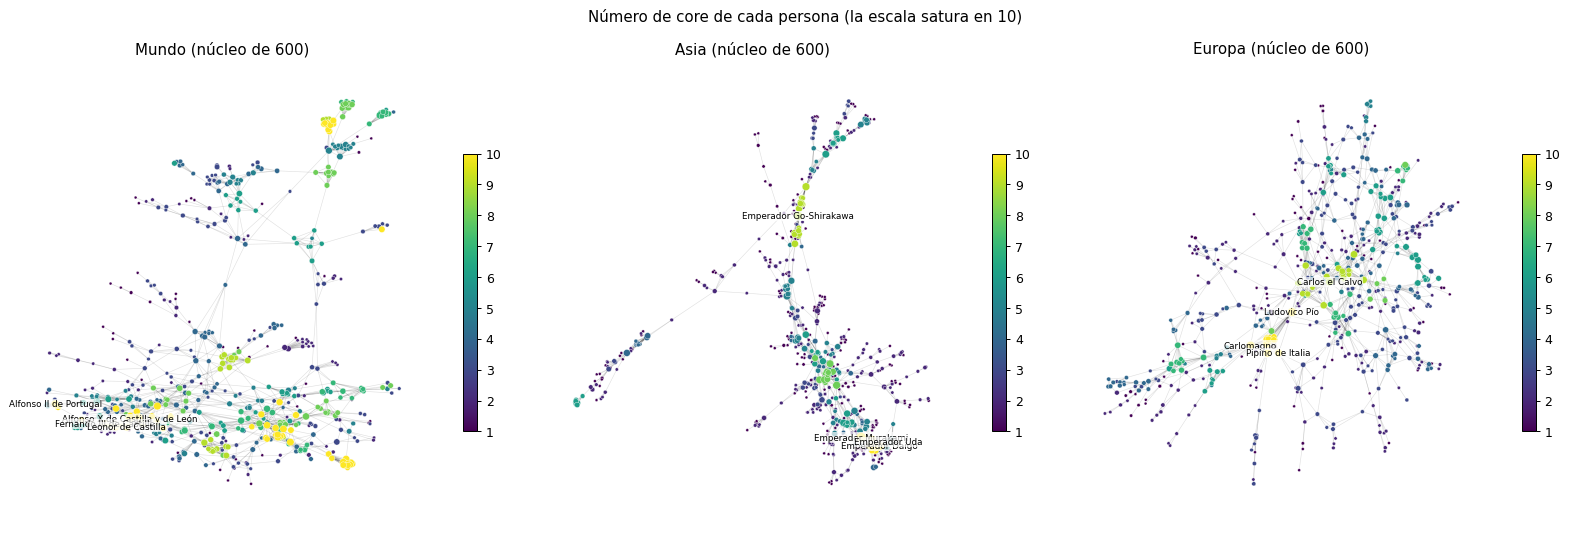

In [12]:
dibujar(color=core, cmap="viridis", vmin=1, vmax=10, barra=True,
        titulo="Número de core de cada persona (la escala satura en 10)")

Las capas forman una cebolla: las personas con un solo enlace quedan en el borde y el centro es más denso. Pero el core más alto vuelve a ser la clique de hermanos más grande: una clique de $n$ nodos es un $(n-1)$-core. En Asia y en el Mundo es el 68-core, con un grupo de 69 hermanos (los hijos de Song Huizong) y el propio emperador; en Europa, el 21-core, con los hijos de Haroldo I de Noruega. La tabla muestra el salto: entre $k = 30$ y $k = 68$ el k-core no cambia, porque sólo queda esa familia.

**¿Y sin hermanos?** Si sacamos los enlaces de hermano (que son los que arman las cliques), ¿queda algún centro denso hecho de matrimonios y filiaciones?

In [13]:
def sin_hermanos(G):
    H = nx.Graph()
    H.add_nodes_from(G.nodes(data=True))
    H.add_edges_from((u, v, d) for u, v, d in G.edges(data=True) if d["weight"] >= 2)
    return H

for region, G in redes.items():
    H = sin_hermanos(G)
    core_sh = nx.core_number(H)
    kmax = max(core_sh.values())
    centro = [v for v in H if core_sh[v] == kmax]
    casas = Counter(H.nodes[v]["casa"] for v in centro if H.nodes[v]["casa"])
    anios = [H.nodes[v]["anio"] for v in centro]
    print(f"{region}: sin hermanos, el máximo es el {kmax}-core con {len(centro)} personas, "
          f"años {min(anios)}–{max(anios)}")
    print(f"   casas: {dict(casas.most_common(5))}")
    print(f"   ejemplos: {', '.join(nombre(H, v) for v in sorted(centro, key=H.degree, reverse=True)[:6])}")

Mundo: sin hermanos, el máximo es el 3-core con 2041 personas, años 710–1441
   casas: {'Casa de Borgoña': 47, 'Casa Real de Aragón': 25, 'Οίκος των Ασκάνια-Βρανδεμβούργου': 24, 'Casa de Estridsson': 18, 'Familia imperial japonesa': 17}
   ejemplos: Emperador Kanmu, Emperador Daigo, Haroldo I de Noruega, Emperador Saga, Carlomagno, Emperador Murakami
Asia: sin hermanos, el máximo es el 3-core con 46 personas, años 737–1281
   casas: {'Familia imperial japonesa': 17, 'Midō-ryū': 3, 'Casa de Armagnac': 3, 'House Millau': 3, 'Casa de Cominges': 1}
   ejemplos: Emperador Kanmu, Emperador Daigo, Emperador Saga, Emperador Murakami, Ninmyō, Fujiwara no Michinaga
Europa: sin hermanos, el máximo es el 3-core con 1804 personas, años 710–1440
   casas: {'Casa de Borgoña': 46, 'Casa Real de Aragón': 25, 'Οίκος των Ασκάνια-Βρανδεμβούργου': 24, 'Casa de Estridsson': 18, 'Casa de Bjälbo': 16}
   ejemplos: Haroldo I de Noruega, Carlomagno, Alfonso IX de León, Carlos de Valois, Federico II Hohenstaufen

Sin hermanos, el k-core máximo es apenas el **3-core**: la red de padres, madres y cónyuges es casi un árbol. Lo que no es árbol son los ciclos que forman los matrimonios entre parientes y entre casas que ya estaban emparentadas. Ese 3-core reúne a unas 2.000 personas de casi todo el período, en su mayoría europeas, más un pequeño núcleo de la familia imperial japonesa y los Fujiwara.

El k-core encuentra un centro, no grupos separados. Para separar las distintas dinastías y épocas necesitamos otra idea: comunidades.

## 4. Comunidades: cortar los puentes (Girvan–Newman, #3C)

Una comunidad es un conjunto de nodos con muchos enlaces adentro y pocos hacia afuera. Para encontrarlas, Girvan y Newman (2002) usan la betweenness de los enlaces.

**Betweenness de un enlace.** Es la betweenness de nodos aplicada a los enlaces: cuántos de los caminos más cortos usan ese enlace,

$$x_{ij} = \sum_{s<t} \frac{\sigma_{st}(i,j)}{\sigma_{st}},$$

donde $\sigma_{st}$ es la cantidad de caminos más cortos entre $s$ y $t$, y $\sigma_{st}(i,j)$ es cuántos de ellos pasan por el enlace $(i,j)$. `nx.edge_betweenness_centrality` divide por la cantidad de pares, así que el resultado es la fracción de pares que se comunican por ese enlace.

Lo vemos en una red chica: dos grupos de 4 nodos, todos conectados entre sí, unidos por un solo enlace.

In [14]:
B = nx.barbell_graph(4, 0)      # grupos {0, 1, 2, 3} y {4, 5, 6, 7}, unidos por el enlace 3–4
xB = nx.edge_betweenness_centrality(B)
for (i, j), donde in [((3, 4), "el puente"), ((0, 3), "adentro, tocando el puente"), ((0, 1), "adentro, lejos del puente")]:
    print(f"   enlace {i}–{j} ({donde}): x = {xB[(i, j)]:.3f}")
print("Pares de nodos:", 8 * 7 // 2)

   enlace 3–4 (el puente): x = 0.571
   enlace 0–3 (adentro, tocando el puente): x = 0.179
   enlace 0–1 (adentro, lejos del puente): x = 0.036
Pares de nodos: 28


Hay 28 pares de nodos. El puente lo usan los $4 \times 4 = 16$ pares que tienen un nodo de cada lado: $16/28 = 0{,}57$. Los enlaces entre comunidades son los de betweenness alta.

En nuestras redes, calcular la betweenness exacta de los 46.000 enlaces requiere un BFS desde cada uno de los 15.000 nodos de la componente gigante. La **estimamos** con `k` nodos de origen al azar (Asia, que es chica, va exacta).

In [15]:
MUESTRA_BETWEENNESS = 200

betweenness_enlaces = {}
for region, G in redes.items():
    Gg = gigante(G)
    k = None if len(Gg) <= 2000 else MUESTRA_BETWEENNESS
    betweenness_enlaces[region] = nx.edge_betweenness_centrality(Gg, k=k, seed=SEMILLA)
    print(f"{region}: enlaces con mayor betweenness")
    for (u, v), b in sorted(betweenness_enlaces[region].items(), key=lambda x: -x[1])[:5]:
        print(f"   {nombre(G, u)} – {nombre(G, v)} ({G[u][v]['tipo']}): {b:.3f}")

Mundo: enlaces con mayor betweenness
   Abaqa – María Paleóloga (conyuge): 0.050
   Hulagu – Abaqa (padre): 0.043
   María Paleóloga – Andrónico II Paleólogo (hermano): 0.039
   Carlomagno – Ludovico Pío (padre): 0.029
   Carlomagno – Pipino el Breve (padre): 0.028


Asia: enlaces con mayor betweenness
   Emperador Shirakawa – Emperador Go-Sanjō (padre): 0.373
   Ninmyō – Emperador Kōkō (padre): 0.361
   Ninmyō – Emperador Saga (padre): 0.347
   Emperador Murakami – Emperador Daigo (padre): 0.334
   Emperador Saga – Emperador Kanmu (padre): 0.253


Europa: enlaces con mayor betweenness
   Carlomagno – Pipino el Breve (padre): 0.050
   Carlomagno – Ludovico Pío (padre): 0.048
   Pipino el Breve – Carlos Martel (padre): 0.043
   Ludovico Pío – Carlos el Calvo (padre): 0.037
   Regintrud – Plectrude (hermano): 0.033


En el Mundo, los enlaces con más betweenness son el puente entre Europa y Asia (el matrimonio de María Paleóloga, hija del emperador bizantino, con el iljan mongol Abaqa) y la línea carolingia, que concentra los caminos entre las casas de Europa occidental.

El algoritmo de Girvan–Newman (`nx.community.girvan_newman`) saca el enlace de mayor betweenness, recalcula la betweenness de todos los enlaces y repite. Como cada recálculo cuesta $O(NL)$, en la red completa es inviable; lo corremos sobre el **núcleo** de cada red.

In [16]:
for region in REGIONES:
    H = nucleos[region]
    primer_corte = next(nx.community.girvan_newman(H))     # primera partición en dos componentes
    print(f"{region}: primer corte del núcleo en {sorted((len(c) for c in primer_corte), reverse=True)} personas")
    for c in sorted(primer_corte, key=len):
        asia = sum(H.nodes[v]["continente"] == "Asia" for v in c) / len(c)
        print(f"   {len(c):3d} personas, {100 * asia:3.0f} % de Asia. "
              f"Con más vínculos: {', '.join(nombre(H, v) for v in sorted(c, key=H.degree, reverse=True)[:5])}")

Mundo: primer corte del núcleo en [446, 154] personas
   154 personas,   3 % de Asia. Con más vínculos: Carlos el Temerario, Anna van Bourgondië, Juan II de Borbón, Isabel de Borbón, Anthony, bastard of Burgundy
   446 personas,   3 % de Asia. Con más vínculos: Alfonso X de Castilla y de León, Fernando III de Castilla, Sancho IV de Castilla, Manuel de Castilla, Blanca de Anjou


Asia: primer corte del núcleo en [395, 205] personas
   205 personas, 100 % de Asia. Con más vínculos: Emperador Go-Shirakawa, Emperador Takakura, Emperador Go-Toba, Emperador Toba, Minamoto no Yoritomo
   395 personas, 100 % de Asia. Con más vínculos: Emperador Murakami, Emperador Daigo, Emperador Suzaku, Gashi-naishinnō, Shōshi-naishinnō


Europa: primer corte del núcleo en [530, 70] personas
    70 personas,   0 % de Asia. Con más vínculos: Pipino el Breve, Carlos Martel, Bernardo (hijo de Carlos Martel), Hiltrud, Auda de Francia
   530 personas,   0 % de Asia. Con más vínculos: Ludovico Pío, Carlomagno, Pipino de Italia, Carlos el Calvo, Luis II de Francia


Los cortes siguen la estructura generacional: en Europa, el primer corte separa a los antepasados de Carlomagno (Carlos Martel, Pipino el Breve) de sus descendientes; en Asia, la rama de Daigo y Murakami (siglo X) de la de Toba, Go-Shirakawa y Takakura (siglo XII). En una genealogía, los puentes suelen ser un único vínculo padre–hijo por el que pasa toda la descendencia.

Girvan–Newman da una jerarquía de cortes pero no dice dónde parar, y es caro. Para decidir qué partición es buena necesitamos una medida: la modularidad.

## 5. Modularidad (#3C)

Una partición es buena si hay más enlaces dentro de las comunidades que los que habría por azar. El azar es el modelo de configuración: la cantidad de enlaces esperada entre $v$ y $w$ es $k_v k_w/2L$. La modularidad suma, sobre los pares de una misma comunidad, la diferencia entre lo real y lo esperado (Newman y Girvan, 2004):

$$Q = \frac{1}{2L}\sum_{v,w}\left[A_{vw} - \frac{k_v k_w}{2L}\right]\delta(c_v,c_w) = \sum_{c}\left[\frac{L_c}{L} - \left(\frac{K_c}{2L}\right)^2\right],$$

donde $L_c$ es la cantidad de enlaces dentro de la comunidad $c$ y $K_c$ es la suma de los grados de sus nodos. En networkx: `nx.community.modularity(G, particion)`.

Primero miramos dos pares de nodos.

In [17]:
L_mundo = mundo.number_of_edges()
for a, b in [("Carlomagno", "Ludovico Pío"), ("Carlomagno", "Gengis Kan")]:
    v, w = resolver(mundo, a), resolver(mundo, b)
    esperado = mundo.degree(v) * mundo.degree(w) / (2 * L_mundo)
    print(f"{a} – {b}: A = {int(mundo.has_edge(v, w))}, esperado por azar = {esperado:.5f}")

Carlomagno – Ludovico Pío: A = 1, esperado por azar = 0.00866
Carlomagno – Gengis Kan: A = 0, esperado por azar = 0.00837


Con una red tan rala, el término del azar es minúsculo: cualquier enlace real "suma mucho" si sus extremos están en la misma comunidad. Por eso podemos esperar modularidades muy altas.

Probamos varias particiones:

- **todos juntos** en una sola comunidad;
- **20 grupos al azar**;
- **por casa** (la columna `casa`; quienes no tienen casa registrada quedan solos);
- **por continente** (sólo tiene sentido en el Mundo);
- **por componente conexa**: cada componente es una comunidad.

In [18]:
def particion_por(G, clave):
    grupos = {}
    for v in G:
        grupos.setdefault(clave(v), set()).add(v)
    return list(grupos.values())

def particiones_de_referencia(G):
    rng = np.random.default_rng(SEMILLA)
    lista = list(G)
    grupo = rng.integers(0, 20, len(lista))
    return {"todos juntos": [set(lista)],
            "20 grupos al azar": [{v for v, g in zip(lista, grupo) if g == i} for i in range(20)],
            "por casa": particion_por(G, lambda v: G.nodes[v]["casa"] or v),
            "por continente": particion_por(G, lambda v: G.nodes[v]["continente"]),
            "por componente conexa": [set(c) for c in nx.connected_components(G)]}

referencia = pd.DataFrame({region: {nombre_p: nx.community.modularity(G, P, weight=None)
                                    for nombre_p, P in particiones_de_referencia(G).items()}
                           for region, G in redes.items()})
referencia.round(3)

,Mundo,Asia,Europa
todos juntos,0.000,0.000,0.000
20 grupos al azar,-0.001,-0.001,0.001
por casa,0.195,0.287,0.122
por continente,0.420,0.000,0.000
por componente conexa,0.433,0.769,0.010


Todos juntos da $Q = 0$ exactamente y los grupos al azar, $Q \approx 0$. El continente da $Q = 0{,}42$ en el Mundo: sólo 835 de los 46.760 enlaces cruzan de Asia a Europa. Las componentes conexas dan $Q = 0{,}77$ en Asia, que está partida en varias familias sin vínculos entre sí, y casi 0 en Europa, que es casi toda una sola componente. Agrupar por casa da algo intermedio (0,12 a 0,29): las casas son grupos reales, pero sólo un 30 % de las personas tiene casa registrada y las casas se unen por matrimonios. Buscamos ahora la partición que maximiza $Q$.

## 6. Algoritmo de Louvain (#3C)

Probar todas las particiones es imposible. Louvain (Blondel et al., 2008) arma la partición de a pasos: en cada paso hace el cambio que más aumenta $Q$ en ese momento, sin volver atrás. Por eso no garantiza encontrar el máximo de $Q$, pero en la práctica llega cerca. Tiene dos fases:

1. Cada nodo empieza en su propia comunidad. Para cada nodo se calcula cuánto cambia $Q$ si se lo mueve a la comunidad de cada vecino, y se lo mueve a la que da el mayor aumento. Se repite hasta que ningún movimiento aumenta $Q$.
2. Cada comunidad se convierte en un supernodo (sus enlaces internos quedan como autoenlaces) y se vuelve a la fase 1 con esta red más chica.

Las dos fases se repiten hasta que $Q$ deja de crecer. Es rápido: con 18.000 nodos tarda un par de segundos (`nx.community.louvain_communities`). Los nodos se recorren en orden aleatorio, así que fijamos la semilla.

In [19]:
def fraccion_entre(G, comunidades):
    etiqueta = {v: i for i, c in enumerate(comunidades) for v in c}
    return sum(etiqueta[u] != etiqueta[v] for u, v in G.edges()) / G.number_of_edges()

def describir_comunidades(G, comunidades, n=10):
    filas = []
    for i, c in enumerate(comunidades[:n]):
        casas = Counter(G.nodes[v]["casa"] for v in c if G.nodes[v]["casa"])
        anios = np.array([G.nodes[v]["anio"] for v in c])
        filas.append({"tamaño": len(c),
                      "con más vínculos": ", ".join(nombre(G, v) for v in sorted(c, key=G.degree, reverse=True)[:3]),
                      "casas más comunes": ", ".join(casas_ for casas_, _ in casas.most_common(2)),
                      "años (10 %–90 %)": f"{int(np.percentile(anios, 10))}–{int(np.percentile(anios, 90))}",
                      "% Asia": round(100 * np.mean([G.nodes[v]["continente"] == "Asia" for v in c]))})
    return pd.DataFrame(filas)

comunidades = {}
for region, G in redes.items():
    comunidades[region] = sorted(nx.community.louvain_communities(G, weight=None, seed=SEMILLA), key=len, reverse=True)
    com = comunidades[region]
    print(f"=== {region}: {len(com)} comunidades, Q = {nx.community.modularity(G, com, weight=None):.3f}, "
          f"enlaces entre comunidades distintas: {100 * fraccion_entre(G, com):.1f} %")
    display(describir_comunidades(G, com))

=== Mundo: 149 comunidades, Q = 0.928, enlaces entre comunidades distintas: 4.9 %


,tamaño,con más vínculos,casas más comunes,años (10 %–90 %),% Asia
0,691,"Leonor Plantagenet, John I, Marquis of Namur, ...","Casa de los Capetos, Casa de Borgoña",1156–1316,4
1,612,"Alberto I de Habsburgo, Otakar I de Bohemia, A...","Οίκος των Ασκάνια-Βρανδεμβούργου, Piastas de S...",1158–1337,0
2,607,"Federico II de Suabia, Judit de Babenberg, Bol...","Casa de Árpad, Premislidas",922–1165,8
3,583,"Yaroslav I el Sabio, Vladimiro I de Kiev, Msti...","Casa de Estridsson, Piasts of Greater Poland",980–1185,0
4,571,"Roberto I de Escocia, Gilbert de Clare, VI con...","Casa de Burgo, casa de Clare",1135–1335,3
5,536,"Inge I de Noruega, Haroldo IV de Noruega, Vald...","Casa de Mecklemburgo, Casa de Estridsson",1124–1320,4
6,528,"Federico de Luxemburgo, Matilde de Suabia, Ger...","Casa de las Ardenas, Aleramici",870–1017,5
7,499,"Everardo I de Wurtemberg, Inés de Württemberg,...","Casa de Zähringen, Urach",1100–1302,17
8,498,"Alfonso X de Castilla y de León, Fernando III ...","Casa de Borgoña, Casa de Ivrea",1199–1338,4
9,476,"Emperador Murakami, Emperador Daigo, Emperador...","Familia imperial japonesa, Uda Genji",887–1071,100


=== Asia: 138 comunidades, Q = 0.929, enlaces entre comunidades distintas: 1.6 %


,tamaño,con más vínculos,casas más comunes,años (10 %–90 %),% Asia
0,236,"Fujiwara no Michinaga, Fujiwara no Yorimune, E...","Familia imperial japonesa, Murakami-Genji",977–1078,100
1,199,"Kublai Kan, Chimkim, Mangala","Borjigin, Onggirat",1215–1323,100
2,194,"Emperador Murakami, Emperador Daigo, Emperador...","Familia imperial japonesa, Hokke",867–969,100
3,176,"Emperatriz Genmei, Príncipe Toneri, Emperador ...","Familia imperial japonesa, Junior Fifth Rank",626–750,100
4,174,"Emperador Kanmu, Emperador Saga, Ninmyō","Saga Genji, Familia imperial japonesa",737–847,100
5,162,"Juan de Ibelín, Amalarico de Tiro, Isabel de I...","Dinastía hetumiana, Ibelín",1136–1315,100
6,136,"Minamoto no Yoritomo, Ushiwakamaru, Ano Zenjō","Clan Hōjō, Kanesawa line",1146–1276,100
7,135,"Bernardo VIII de Cominges, Henry II of Rodez, ...","Casa de Armagnac, House Millau",1127–1315,100
8,130,"Song Zhenzong, Song Taizong, Zhao Yuanwo",House of Zhao,939–1042,100
9,126,"Emperador Go-Daigo, Emperador Go-Fukakusa, Emp...","Jimyōin line, Daikakuji line",1243–1331,100


=== Europa: 155 comunidades, Q = 0.909, enlaces entre comunidades distintas: 7.0 %


,tamaño,con más vínculos,casas más comunes,años (10 %–90 %),% Asia
0,542,"Otón I de Hesse, Birger Jarl, Mechthild von He...","Casa de Mecklemburgo, Οίκος των Ασκάνια-Βρανδε...",1173–1337,0
1,536,"Carlos de Valois, Felipe de Tarento, Leonor de...","Casa de Anjou-Sicilia, House of Brabant",1217–1340,0
2,449,"Eduardo I de Inglaterra, Eduardo II de Inglate...","casa de Clare, de Beauchamp family",1190–1338,0
3,392,"Yaroslav I el Sabio, Vladimiro I de Kiev, Bole...","Premislidas, Casa de Árpad",928–1100,0
4,381,"Alberto I de Habsburgo, Otakar I de Bohemia, A...","Piastas de Silesia, Piasts of Mazovia",1207–1339,0
5,353,"Leonor Plantagenet, Juan I de Inglaterra, Marí...","House of Vianden, Casa de los Capetos",1082–1241,0
6,347,"Matilde de Suabia, Gisela de Suabia, Gerberga ...","Dinastía sajona, Casa de Árpad",847–995,0
7,329,"Alfonso VI de León, Almodis de la Marca, Cleme...","Familia Montgomerie, Casal de Pallars",953–1100,0
8,323,"Alfonso II de Portugal, Sancho I de Portugal, ...","Casa de Sousa, Casa de Riba Duero",1075–1200,0
9,314,"Gerhard V of Jülich, Guillermo V de Jülich, Wa...","House of Cleves, House of Loon",1157–1336,0


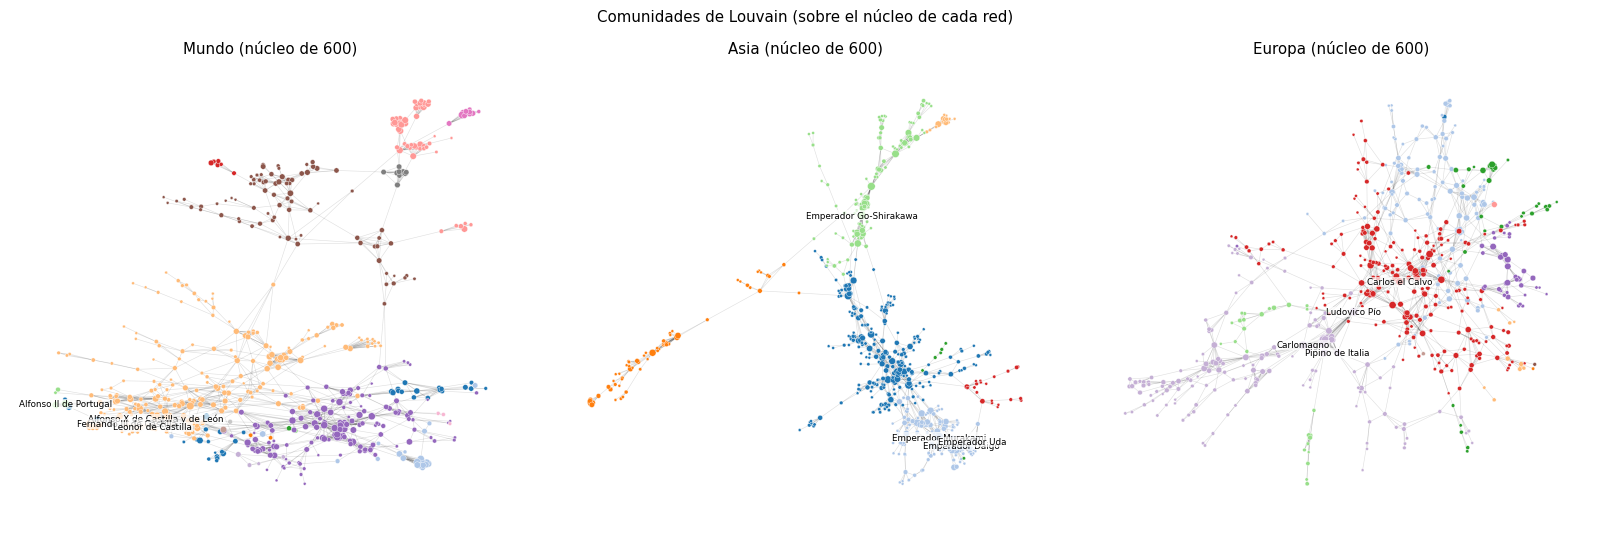

In [20]:
# Coloreamos el núcleo con las comunidades encontradas en la red completa (cada color, una comunidad)
etiquetas = {}
for region in REGIONES:
    en_nucleo = sorted({i for i, c in enumerate(comunidades[region]) for v in c if v in nucleos[region]})
    color_de = {i: j % 20 for j, i in enumerate(en_nucleo)}          # colores 0..19 para las presentes
    etiquetas[region] = {v: color_de[i] for i, c in enumerate(comunidades[region]) for v in c if v in nucleos[region]}
dibujar(color=etiquetas, cmap="tab20", vmin=0, vmax=19, titulo="Comunidades de Louvain (sobre el núcleo de cada red)")

Las comunidades son **dinastías en una época y una región**: una casa (o un grupo de casas que se casan entre sí) durante unas pocas generaciones. Por ejemplo, los Capetos y Borgoña en 1156–1316, los Premislidas y Árpad en 928–1100, los gengiskánidas en 1215–1323 o los Fujiwara y la familia imperial japonesa en 977–1078. La columna de años muestra que cada comunidad abarca uno o dos siglos, no todo el período: la red es una cadena de generaciones y Louvain la corta en tramos. Sólo entre el 1,6 % y el 7 % de los enlaces unen comunidades distintas, mucho menos que en una red social.

¿Las comunidades coinciden con las casas? Para las personas con casa registrada, medimos qué fracción pertenece a la casa más común de su comunidad (**pureza**) y, al revés, en cuántas comunidades se reparte cada casa.

In [21]:
for region, G in redes.items():
    comunidad_de = {v: i for i, c in enumerate(comunidades[region]) for v in c}
    df = pd.DataFrame([(comunidad_de[v], G.nodes[v]["casa"]) for v in G if G.nodes[v]["casa"]],
                      columns=["comunidad", "casa"])
    pureza = df.groupby("comunidad")["casa"].agg(lambda s: s.value_counts().iloc[0]).sum() / len(df)
    reparto = df.groupby("casa")["comunidad"].nunique()
    grandes = df["casa"].value_counts().head(3).index
    print(f"{region}: pureza = {pureza:.2f}. Casas más grandes y en cuántas comunidades caen: "
          f"{ {c: int(reparto[c]) for c in grandes} }")

Mundo: pureza = 0.29. Casas más grandes y en cuántas comunidades caen: {'House of Li': 6, 'House of Zhao': 3, 'Casa de Borgoña': 5}
Asia: pureza = 0.62. Casas más grandes y en cuántas comunidades caen: {'House of Li': 10, 'House of Zhao': 4, 'Familia imperial japonesa': 8}
Europa: pureza = 0.24. Casas más grandes y en cuántas comunidades caen: {'Casa de Borgoña': 6, 'Casa de Wessex': 4, 'Hårfagreætta': 3}


La pureza es baja en Europa (alrededor de 0,25) y más alta en Asia (0,62). Las comunidades no son casas: mezclan varias casas que se casan entre sí, y cada casa grande se reparte en varias comunidades, una por época (la Casa de Borgoña cae en 6, la House of Li en 10). Las comunidades son grupos de parentesco efectivo, no las etiquetas dinásticas.

### Meta-comunidades

`nx.community.louvain_partitions` devuelve la partición al final de cada pasada.

In [22]:
for region, G in redes.items():
    print(f"{region}:")
    for nivel, P in enumerate(nx.community.louvain_partitions(G, weight=None, seed=SEMILLA)):
        print(f"   pasada {nivel + 1}: {len(P):5d} comunidades, Q = {nx.community.modularity(G, P, weight=None):.3f}")

Mundo:


   pasada 1:  3820 comunidades, Q = 0.736


   pasada 2:  1087 comunidades, Q = 0.876
   pasada 3:   272 comunidades, Q = 0.922
   pasada 4:   153 comunidades, Q = 0.928
   pasada 5:   149 comunidades, Q = 0.928
Asia:


   pasada 1:   750 comunidades, Q = 0.836
   pasada 2:   260 comunidades, Q = 0.915
   pasada 3:   144 comunidades, Q = 0.928
   pasada 4:   138 comunidades, Q = 0.929
Europa:


   pasada 1:  3132 comunidades, Q = 0.684
   pasada 2:   902 comunidades, Q = 0.851


   pasada 3:   255 comunidades, Q = 0.903
   pasada 4:   157 comunidades, Q = 0.908
   pasada 5:   155 comunidades, Q = 0.909


La primera pasada junta a las personas en miles de comunidades chicas (familias nucleares, básicamente). Las siguientes juntan esas comunidades en meta-comunidades, hasta que $Q$ deja de crecer.

### Robustez: semillas, resolución y pesos

Probamos otras semillas, la resolución $\gamma$ y los pesos. La resolución multiplica el término del azar, $Q_\gamma = \sum_c [L_c/L - \gamma\,(K_c/2L)^2]$: con $\gamma > 1$ salen comunidades más chicas y con $\gamma < 1$ más grandes. En la tabla, $Q$ siempre se evalúa con $\gamma = 1$. Con pesos, un vínculo padre/madre (peso 3) cuenta tres veces lo que uno de hermano.

In [23]:
filas = []
for region, G in redes.items():
    for semilla in range(5):
        P = nx.community.louvain_communities(G, weight=None, seed=semilla)
        filas.append((region, "no", 1.0, semilla, len(P), nx.community.modularity(G, P, weight=None)))
    for gamma in [0.1, 0.5, 2.0]:
        P = nx.community.louvain_communities(G, weight=None, resolution=gamma, seed=SEMILLA)
        filas.append((region, "no", gamma, SEMILLA, len(P), nx.community.modularity(G, P, weight=None)))
    P = nx.community.louvain_communities(G, weight="weight", seed=SEMILLA)
    filas.append((region, "sí", 1.0, SEMILLA, len(P), nx.community.modularity(G, P, weight="weight")))

pd.DataFrame(filas, columns=["red", "pesos", "resolución γ", "semilla", "comunidades", "Q"]).round(3)

,red,pesos,resolución γ,semilla,comunidades,Q
0,Mundo,no,1.0,0,150,0.929
1,Mundo,no,1.0,1,144,0.929
2,Mundo,no,1.0,2,148,0.929
3,Mundo,no,1.0,3,149,0.929
4,Mundo,no,1.0,4,148,0.929
5,Mundo,no,0.1,42,100,0.839
6,Mundo,no,0.5,42,126,0.924
7,Mundo,no,2.0,42,189,0.926
8,Mundo,sí,1.0,42,158,0.923
9,Asia,no,1.0,0,138,0.929


Con distintas semillas $Q$ cambia en la tercera decimal, pero la cantidad de comunidades cambia: hay muchas particiones con $Q$ casi máximo y Louvain encuentra una de ellas (Good, de Montjoye y Clauset, 2010). La resolución cambia el tamaño de las comunidades, y no hay un tamaño correcto. Además, la modularidad no puede ver comunidades por debajo de cierto tamaño, que depende de $L$ (límite de resolución, Fortunato y Barthélemy, 2007).

Ojo con el número de comunidades: incluye a cada persona aislada y a cada componente chica, que son comunidades "obligadas".

## 7. Mundo, Asia y Europa

Juntamos todo en una tabla para las tres redes.

In [24]:
def resumen(region):
    G = redes[region]
    N, L = G.number_of_nodes(), G.number_of_edges()
    com = comunidades[region]
    return {"N": N, "L": L, "<k>": 2 * L / N,
            "<C>": nx.average_clustering(G), "transitividad": nx.transitivity(G),
            "clique máx.": max(len(q) for q in cliques[region]),
            "k-core máx.": max(core[region].values()),
            "k-core máx. sin hermanos": max(nx.core_number(sin_hermanos(G)).values()),
            "comunidades": len(com),
            "comunidades con 20+": sum(len(c) >= 20 for c in com),
            "Q": nx.community.modularity(G, com, weight=None),
            "% enlaces entre com.": 100 * fraccion_entre(G, com)}

pd.DataFrame({region: resumen(region) for region in REGIONES}).T.round(3)

,N,L,<k>,<C>,transitividad,clique máx.,k-core máx.,k-core máx. sin hermanos,comunidades,comunidades con 20+,Q,% enlaces entre com.
Mundo,18060.0,46760.0,5.178,0.436,0.692,69.0,68.0,3.0,149.0,78.0,0.928,4.921
Asia,4275.0,14728.0,6.890,0.441,0.804,69.0,68.0,3.0,138.0,44.0,0.929,1.596
Europa,13785.0,31197.0,4.526,0.431,0.492,22.0,21.0,3.0,155.0,74.0,0.909,7.007


Para mirar las comunidades de la red completa en Gephi, guardamos un CSV con la comunidad y el número de core de cada persona en cada red. En Gephi: abrir el `.gexf` generado en `01 - Metricas`, ir a *Data Laboratory → Import Spreadsheet*, elegir este CSV como tabla de nodos y marcar la opción de unir por `Id` con los nodos existentes. Después: *Appearance → Nodes → Color → Partition → comunidad_mundo*.

In [25]:
salida = nodos[["Id", "Label", "continente", "casa", "anio"]].copy()
for region in REGIONES:
    comunidad_de = {v: i for i, c in enumerate(comunidades[region]) for v in c}
    salida[f"comunidad_{region.lower()}"] = salida["Id"].map(comunidad_de).astype("Int64")
    salida[f"core_{region.lower()}"] = salida["Id"].map(core[region]).astype("Int64")

CARPETA_SALIDA = Path("gexf")
CARPETA_SALIDA.mkdir(exist_ok=True)
salida.to_csv(CARPETA_SALIDA / "comunidades_louvain.csv", index=False)
print("Guardado:", (CARPETA_SALIDA / "comunidades_louvain.csv").resolve())
salida.head()

Guardado: C:\Users\HP\Tomas\Ciencia de datos\2do año\Redes Complejas\Redes-Complejas\colabs-analisis\gexf\comunidades_louvain.csv


,Id,Label,continente,casa,anio,comunidad_mundo,core_mundo,comunidad_asia,core_asia,comunidad_europa,core_europa
0,Q7419,Emperador Yangdi,Asia,dinastía Sui,569,56,6,17,6,<NA>,<NA>
1,Q9458,Mahoma,Asia,Banu Háshim,571,47,3,10,3,<NA>,<NA>
2,Q39619,Ali Ibn Abi Talib,Asia,NaN,599,47,1,10,1,<NA>,<NA>
3,Q22968293,Samson,Europa,NaN,573,28,8,<NA>,<NA>,38,8
4,Q22968296,Dagobert,Europa,NaN,580,28,8,<NA>,<NA>,38,8


## Posibles continuaciones

1. **Club de karate.** `nx.karate_club_graph()` es la red de Zachary (1977) de la teórica #3B. El atributo `club` de cada nodo dice con quién se fue cada socio después de la pelea. Corran Louvain y Girvan–Newman y comparen con la división real.
2. **Girvan–Newman con modularidad.** Recorran los primeros 15 niveles de `nx.community.girvan_newman(nucleos["Europa"])` y calculen $Q$ en cada uno. ¿En qué nivel es máximo? ¿Cómo se compara con Louvain sobre el mismo núcleo?
3. **Pesos.** Comparen las comunidades con `weight=None` y con `weight="weight"`. ¿Qué personas cambian de comunidad y por qué?
4. **Sin hermanos.** Repitan Louvain sobre `sin_hermanos(G)`. Las comunidades, ¿se parecen más a las casas?
5. **Comunidades y tiempo.** Para cada comunidad de Europa, grafiquen el año mediano contra el tamaño. ¿Hay épocas con comunidades más grandes? ¿Coinciden con épocas de muchos matrimonios entre casas?
6. **Otros algoritmos.** Prueben `nx.community.label_propagation_communities` y `nx.community.greedy_modularity_communities` (este último tarda más). ¿Llegan a la misma $Q$?

## Resumen

- El clustering de las tres redes es cientos de veces mayor que en una red al azar con los mismos $N$ y $L$, pero las distancias son mucho más largas: una genealogía tiene grupos muy cohesivos y no es un "mundo pequeño".
- Las cliques más grandes son grupos de hermanos con sus padres: un efecto de cómo se registran los vínculos. La clique es una definición de grupo frágil.
- El k-core máximo vuelve a ser esa clique de hermanos. Sin los enlaces de hermano, la red es casi un árbol (el k-core máximo es el 3-core).
- La modularidad es altísima ($Q > 0{,}9$): casi todos los enlaces quedan dentro de las comunidades de Louvain, que son grupos de casas emparentadas en una región y en una época, no las casas de la columna `casa`.

## Referencias

- D. J. Watts y S. H. Strogatz, Nature 393, 440 (1998): coeficiente de clustering.
- W. W. Zachary, J. Anthropol. Res. 33, 452 (1977): club de karate.
- S. B. Seidman, Social Networks 5, 269 (1983): k-cores.
- M. Girvan y M. E. J. Newman, PNAS 99, 7821 (2002): comunidades por betweenness de enlaces.
- M. E. J. Newman y M. Girvan, Phys. Rev. E 69, 026113 (2004): modularidad.
- V. D. Blondel, J.-L. Guillaume, R. Lambiotte y E. Lefebvre, J. Stat. Mech. P10008 (2008): algoritmo de Louvain.
- S. Fortunato y M. Barthélemy, PNAS 104, 36 (2007): límite de resolución.
- B. H. Good, Y.-A. de Montjoye y A. Clauset, Phys. Rev. E 81, 046106 (2010): muchas particiones con modularidad casi máxima.
- S. Fortunato, Phys. Rep. 486, 75 (2010): revisión de detección de comunidades.
- A.-L. Barabási, *Network Science* (Cambridge University Press, 2016), cap. 9: comunidades. Libre en networksciencebook.com.
- Datos: Wikidata, https://query.wikidata.org/sparql.